# D+1 Electricity Demand Forecasting for Peninsular Spain

### Model development, temporal validation and out-of-sample evaluation

This notebook develops an hourly D+1 electricity-demand forecast for
peninsular Spain using historical demand, calendar information and
weather forecasts.

Model selection uses expanding-window validation over 2021–2024.
The final test period, starting in 2025, is kept out of feature and
hyperparameter selection.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays

%load_ext autoreload
%autoreload 2

from energy_forecasting.features import (
    add_calendar_features,
    add_demand_lags,
    add_recent_demand_features,
)

from energy_forecasting.evaluation import regression_metrics

In [5]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

## 1. Data and feature construction

In [6]:
real_demand = pd.read_csv(
    project_root / "data" / "processed" / "real_demand_hourly.csv"
)

real_demand["datetime_utc"] = pd.to_datetime(
    real_demand["datetime_utc"],
    utc=True,
)

real_demand = (
    real_demand
    .set_index("datetime_utc")
    .rename(columns={"value": "demand_MW"})
)

In [7]:
real_demand = add_calendar_features(real_demand)
real_demand = add_demand_lags(real_demand)
real_demand = add_recent_demand_features(real_demand)

In [8]:
print("Rows:", len(real_demand))
print("Start:", real_demand.index.min())
print("End:", real_demand.index.max())
print("Duplicate timestamps:", real_demand.index.duplicated().sum())
print("Missing demand:", real_demand["demand_MW"].isna().sum())

Rows: 93863
Start: 2015-12-31 23:00:00+00:00
End: 2026-09-15 21:00:00+00:00
Duplicate timestamps: 0
Missing demand: 0


### Recent-demand feature sanity check

Verify that the recent-demand feature uses only observations available
before the D−1 12:00 local forecasting cutoff.

In [9]:
target_day = pd.Timestamp("2024-07-15")

In [10]:
start = pd.Timestamp(
    "2024-07-14 06:00",
    tz="Europe/Madrid",
)

end = pd.Timestamp(
    "2024-07-14 12:00",
    tz="Europe/Madrid",
)

expected = real_demand.loc[
    (real_demand["datetime_local"] >= start)
    & (real_demand["datetime_local"] < end),
    "demand_MW",
].mean()

In [11]:
observed = real_demand.loc[
    real_demand["datetime_local"].dt.date
    == target_day.date(),
    "recent_demand_6hs_mean",
].iloc[0]

print(expected, observed)
assert np.isclose(expected, observed)

21835.708333333336 21835.70833337307


In [12]:
from energy_forecasting.redata import (
    download_annual_demand_ccaa,
)

import json

In [13]:
annual_demand_raw_dir = (
    project_root
    / "data"
    / "raw"
    / "ree_annual_demand_ccaa"
)

region_ids = json.loads(
    (annual_demand_raw_dir / "regions.json").read_text()
)


In [14]:
download_annual_demand_ccaa(
    region_ids=region_ids,
    start_year=2013,
    end_year=2024,
    output_dir=annual_demand_raw_dir,
)

In [15]:
annual_demand_records = []

for region, geo_id in region_ids.items():
    for year in range(2013, 2025):
        response_path = (
            annual_demand_raw_dir
            / f"{geo_id}_{year}.json"
        )

        payload = json.loads(
            response_path.read_text()
        )

        demand_indicators = [
            item
            for item in payload.get("included", [])
            if item["attributes"]["title"] == "Demanda"
        ]

        if len(demand_indicators) != 1:
            raise ValueError(
                f"Expected one demand indicator: {region}, {year}"
            )

        observations = demand_indicators[0]["attributes"]["values"]

        if (
            len(observations) != 1
            or pd.Timestamp(
                observations[0]["datetime"]
            ).year != year
        ):
            raise ValueError(
                f"Expected one annual observation: {region}, {year}"
            )

        annual_demand_records.append({
            "year": year,
            "region": region,
            "demand_GWh": observations[0]["value"] / 1000,
        })

In [16]:
annual_demand_ccaa = (
    pd.DataFrame(annual_demand_records)
    .sort_values(["year", "region"])
    .reset_index(drop=True)
)

assert len(annual_demand_ccaa) == 12 * 17
assert not annual_demand_ccaa.duplicated(
    ["year", "region"]
).any()
assert annual_demand_ccaa["demand_GWh"].notna().all()
assert (annual_demand_ccaa["demand_GWh"] > 0).all()

In [17]:
annual_demand_ccaa

,year,region,demand_GWh
0,2013,Andalucía,38073.498055
1,2013,Aragón,10102.310158
2,2013,Asturias,10414.051910
3,2013,Canarias,8599.500564
4,2013,Cantabria,4389.155169
...,...,...,...
199,2024,Islas Baleares,6063.947211
200,2024,La Rioja,1531.179156
201,2024,Navarra,4742.059824
202,2024,País Vasco,15002.547251


In [18]:
non_peninsular = [
    "Canarias",
    "Islas Baleares",
]

annual_demand_peninsular = annual_demand_ccaa[
    ~annual_demand_ccaa["region"].isin(non_peninsular)
].copy()

In [19]:
weights_records = []

for year in range(2016, 2026):
    trailing = annual_demand_peninsular[
        annual_demand_peninsular["year"].between(
            year - 3,
            year - 1,
        )
    ]

    demand_by_region = (
        trailing
        .groupby("region")["demand_GWh"]
        .sum()
    )

    weights = demand_by_region / demand_by_region.sum()

    for region, weight in weights.items():
        weights_records.append({
            "year": year,
            "region": region,
            "demand_weight": weight,
        })

regional_weights = pd.DataFrame(weights_records)

In [20]:
# Freeze the last weights estimable from training-period data
# throughout the out-of-sample test period.

weights_2026 = (
    regional_weights[
        regional_weights["year"] == 2025
    ]
    .assign(year=2026)
)

regional_weights = pd.concat(
    [regional_weights, weights_2026],
    ignore_index=True,
)

In [21]:
weights_2025 = (
    regional_weights.loc[
        regional_weights["year"] == 2025
    ]
    .set_index("region")["demand_weight"]
    .sort_index()
)

weights_2026 = (
    regional_weights.loc[
        regional_weights["year"] == 2026
    ]
    .set_index("region")["demand_weight"]
    .sort_index()
)

assert weights_2025.index.equals(weights_2026.index)
assert np.allclose(weights_2025, weights_2026)

In [22]:
weight_sums = (
    regional_weights
    .groupby("year")["demand_weight"]
    .sum()
)

print(weight_sums)

assert np.allclose(
    weight_sums.to_numpy(),
    1.0,
)

year
2016    1.0
2017    1.0
2018    1.0
2019    1.0
2020    1.0
2021    1.0
2022    1.0
2023    1.0
2024    1.0
2025    1.0
2026    1.0
Name: demand_weight, dtype: float64


### Regional holiday-demand exposure

In [23]:
region_to_subdiv = {
    "Andalucía": "AN",
    "Aragón": "AR",
    "Asturias": "AS",
    "Cantabria": "CB",
    "Castilla y León": "CL",
    "Castilla-La Mancha": "CM",
    "Cataluña": "CT",
    "Comunidad Valenciana": "VC",
    "Extremadura": "EX",
    "Galicia": "GA",
    "Comunidad de Madrid": "MD",
    "Región de Murcia": "MC",
    "Navarra": "NC",
    "País Vasco": "PV",
    "La Rioja": "RI",
}

records = []

for year in range(2016, 2027):
    weights_year = (
        regional_weights[
            regional_weights["year"] == year
        ]
        .set_index("region")["demand_weight"]
    )

    regional_calendars = {
        region: holidays.country_holidays(
            "ES",
            subdiv=subdiv,
            years=[year],
        )
        for region, subdiv in region_to_subdiv.items()
    }

    dates = pd.date_range(
        f"{year}-01-01",
        f"{year}-12-31",
        freq="D",
    )

    for date in dates:
        d = date.date()

        exposure = sum(
            weights_year[region]
            for region in region_to_subdiv
            if d in regional_calendars[region]
        )

        records.append({
            "date": d,
            "year": year,
            "holiday_demand_exposure": exposure,
        })

holiday_exposure = pd.DataFrame(records)

In [24]:
exposure_by_date = (
    holiday_exposure
    .assign(
        date=pd.to_datetime(
            holiday_exposure["date"]
        ).dt.date
    )
    .set_index("date")[
        "holiday_demand_exposure"
    ]
)

assert exposure_by_date.index.is_unique

real_demand["holiday_demand_exposure"] = (
    real_demand["datetime_local"]
    .dt.date
    .map(exposure_by_date)
)

assert (
    real_demand["holiday_demand_exposure"]
    .notna()
    .all()
)

In [25]:
christmas_2025 = real_demand.loc[
    real_demand["datetime_local"].dt.date
    == pd.Timestamp("2025-12-25").date(),
    "holiday_demand_exposure",
].unique()

print(christmas_2025)

assert len(christmas_2025) == 1
assert np.isclose(christmas_2025[0], 1.0)

[1.]


### Weather forecasts and modeling dataset

In [26]:
weather_d1_hourly = pd.read_parquet(
    project_root
    / "data"
    / "processed"
    / "weather_d1_hourly.parquet"
)

In [27]:
target = "demand_MW"

categorical_features = [
    "hour",
    "day_of_week",
    "month",
]

numeric_features = [
    "lag_48",
    "lag_168",
    "lag_336",
    "lag_504",
    "recent_demand_6hs_mean",
    "recent_regime",
    "holiday_demand_exposure",
]

weather_features = [
    "temp_a_coruna_C",
    "temp_barcelona_C",
    "temp_bilbao_C",
    "temp_madrid_C",
    "temp_malaga_C",
    "temp_sevilla_C",
    "temp_valencia_C",
    "temp_zaragoza_C",
]

features = (
    numeric_features
    + weather_features
    + categorical_features
)

In [28]:
dataset = real_demand.merge(
    weather_d1_hourly,
    left_index=True,
    right_index=True,
    how="left",
    validate="one_to_one",
)

dataset = dataset.dropna(
    subset=[target] + features
)

In [29]:
print("Shape:", dataset.shape)
print("Start:", dataset.index.min())
print("End:", dataset.index.max())
print("Duplicate timestamps:", dataset.index.duplicated().sum())
print(
    "Missing modeling values:",
    dataset[[target] + features].isna().sum().sum(),
)

Shape: (92999, 21)
Start: 2016-01-21 23:00:00+00:00
End: 2026-08-31 21:00:00+00:00
Duplicate timestamps: 0
Missing modeling values: 0


## 2. Temporal validation design

Model development uses expanding-window validation.

Each validation fold contains one complete calendar year:

- train through 2020 → validate on 2021
- train through 2021 → validate on 2022
- train through 2022 → validate on 2023
- train through 2023 → validate on 2024

After model selection, the final model is trained on all observations
through 2024 and evaluated once on the out-of-sample period beginning
in 2025.

All boundaries are defined in Europe/Madrid local time.

In [30]:
validation_years = [2021, 2022, 2023, 2024]

train_folds = []
validation_folds = []

for year in validation_years:
    validation_start = pd.Timestamp(
        f"{year}-01-01",
        tz="Europe/Madrid",
    )
    validation_end = pd.Timestamp(
        f"{year + 1}-01-01",
        tz="Europe/Madrid",
    )

    train = dataset[
        dataset["datetime_local"] < validation_start
    ]

    validation = dataset[
        (dataset["datetime_local"] >= validation_start)
        & (dataset["datetime_local"] < validation_end)
    ]

    train_folds.append(train)
    validation_folds.append(validation)

In [31]:
test_start = pd.Timestamp(
    "2025-01-01",
    tz="Europe/Madrid",
)

train_final = dataset[
    dataset["datetime_local"] < test_start
]

test = dataset[
    dataset["datetime_local"] >= test_start
]

In [32]:
for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    print(
        year,
        "train:", len(train),
        "validation:", len(validation),
        "validation start:", validation["datetime_local"].min(),
        "validation end:", validation["datetime_local"].max(),
    )

print()
print("Final train:", len(train_final))
print(
    train_final["datetime_local"].min(),
    "→",
    train_final["datetime_local"].max(),
)

print("Test:", len(test))
print(
    test["datetime_local"].min(),
    "→",
    test["datetime_local"].max(),
)

2021 train: 43344 validation: 8760 validation start: 2021-01-01 00:00:00+01:00 validation end: 2021-12-31 23:00:00+01:00
2022 train: 52104 validation: 8760 validation start: 2022-01-01 00:00:00+01:00 validation end: 2022-12-31 23:00:00+01:00
2023 train: 60864 validation: 8760 validation start: 2023-01-01 00:00:00+01:00 validation end: 2023-12-31 23:00:00+01:00
2024 train: 69624 validation: 8784 validation start: 2024-01-01 00:00:00+01:00 validation end: 2024-12-31 23:00:00+01:00

Final train: 78408
2016-01-22 00:00:00+01:00 → 2024-12-31 23:00:00+01:00
Test: 14591
2025-01-01 00:00:00+01:00 → 2026-08-31 23:00:00+02:00


In [33]:
assert all(
    train.index.max() < validation.index.min()
    for train, validation
    in zip(train_folds, validation_folds)
)

assert train_final.index.max() < test.index.min()

## 3. Exploratory feature relationships

The following diagnostics use development-period data only (through
2024). They illustrate the economic and statistical motivation for
some of the features used later in the forecasting models.

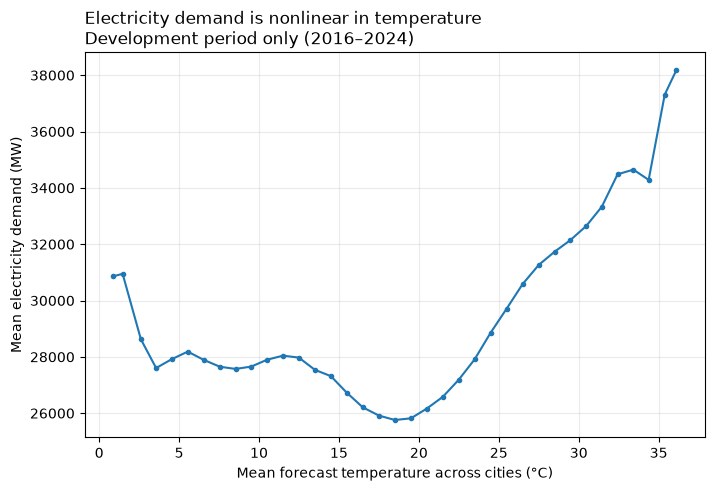

In [34]:
eda_hourly = train_final[
    [target] + weather_features
].copy()

eda_hourly["mean_temperature_C"] = (
    eda_hourly[weather_features].mean(axis=1)
)

temperature_bins = pd.cut(
    eda_hourly["mean_temperature_C"],
    bins=np.arange(
        np.floor(eda_hourly["mean_temperature_C"].min()),
        np.ceil(eda_hourly["mean_temperature_C"].max()) + 2,
        1,
    ),
)

temperature_profile = (
    eda_hourly
    .groupby(temperature_bins, observed=True)
    .agg(
        temperature_C=("mean_temperature_C", "mean"),
        demand_MW=(target, "mean"),
    )
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    temperature_profile["temperature_C"],
    temperature_profile["demand_MW"],
    marker="o",
    markersize=3,
)

ax.set_xlabel("Mean forecast temperature across cities (°C)")
ax.set_ylabel("Mean electricity demand (MW)")
ax.set_title(
    "Electricity demand is nonlinear in temperature\n"
    "Development period only (2016–2024)",
    loc="left",
)

ax.grid(alpha=0.25)
plt.show()

In [35]:
eda_daily = (
    train_final
    .assign(
        local_date=train_final["datetime_local"].dt.date
    )
    .groupby("local_date")
    .agg(
        demand_MW=(target, "mean"),
        lag_168=("lag_168", "mean"),
        recent_demand_6hs_mean=(
            "recent_demand_6hs_mean",
            "first",
        ),
        recent_regime=(
            "recent_regime",
            "first",
        ),
    )
)

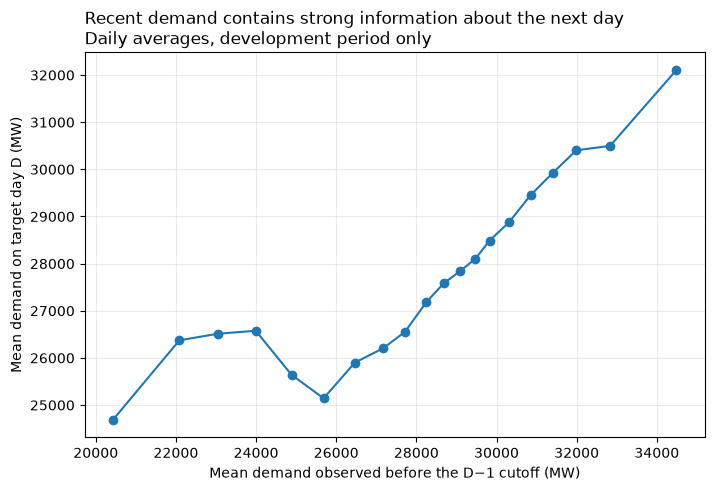

In [36]:
recent_bins = pd.qcut(
    eda_daily["recent_demand_6hs_mean"],
    q=20,
    duplicates="drop",
)

recent_profile = (
    eda_daily
    .groupby(recent_bins, observed=True)
    .agg(
        recent_demand_MW=("recent_demand_6hs_mean", "mean"),
        target_demand_MW=("demand_MW", "mean"),
    )
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    recent_profile["recent_demand_MW"],
    recent_profile["target_demand_MW"],
    marker="o",
)

ax.set_xlabel("Mean demand observed before the D−1 cutoff (MW)")
ax.set_ylabel("Mean demand on target day D (MW)")
ax.set_title(
    "Recent demand contains strong information about the next day\n"
    "Daily averages, development period only",
    loc="left",
)

ax.grid(alpha=0.25)
plt.show()

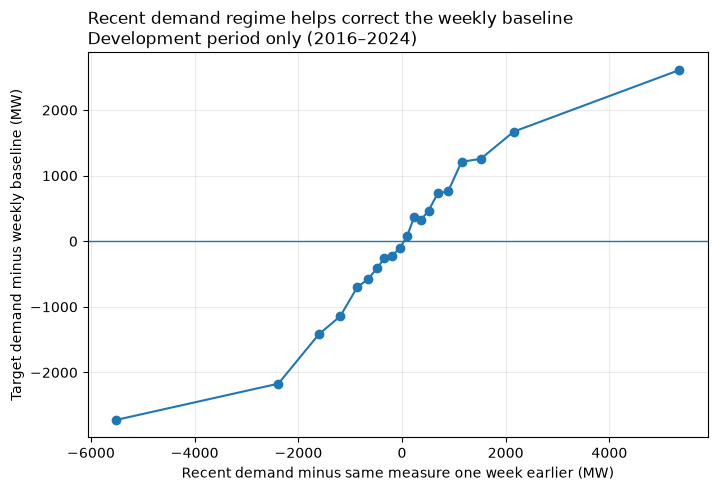

In [37]:
eda_daily["deviation_from_weekly_baseline_MW"] = (
    eda_daily["demand_MW"]
    - eda_daily["lag_168"]
)

regime_bins = pd.qcut(
    eda_daily["recent_regime"],
    q=20,
    duplicates="drop",
)

regime_profile = (
    eda_daily
    .groupby(regime_bins, observed=True)
    .agg(
        recent_regime_MW=("recent_regime", "mean"),
        future_deviation_MW=(
            "deviation_from_weekly_baseline_MW",
            "mean",
        ),
    )
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.axhline(0, linewidth=1)

ax.plot(
    regime_profile["recent_regime_MW"],
    regime_profile["future_deviation_MW"],
    marker="o",
)

ax.set_xlabel(
    "Recent demand minus same measure one week earlier (MW)"
)
ax.set_ylabel(
    "Target demand minus weekly baseline (MW)"
)

ax.set_title(
    "Recent demand regime helps correct the weekly baseline\n"
    "Development period only (2016–2024)",
    loc="left",
)

ax.grid(alpha=0.25)
plt.show()

## 4. Baselines and model development
Two historical-demand baselines are evaluated on the same
expanding-window validation periods used for model selection:

- `lag_48`: demand 48 elapsed hours earlier.
- `lag_168`: demand one week earlier.

The weekly baseline is expected to be substantially stronger because
electricity demand has a pronounced weekly cycle.

In [38]:
baseline_records = []

for year, validation in zip(
    validation_years,
    validation_folds,
):
    for baseline in ["lag_48", "lag_168"]:

        metrics = regression_metrics(
            validation[target],
            validation[baseline],
        )

        baseline_records.append({
            "year": year,
            "model": baseline,
            **metrics,
        })

baseline_metrics = (
    pd.DataFrame(baseline_records)
    .set_index(["year", "model"])
)

baseline_metrics

MAE         RMSE      MAPE
year model                                      
2021 lag_48   2630.327759  3527.767029  0.096449
     lag_168  1264.777511  1991.852352  0.045132
2022 lag_48   2694.821480  3597.877191  0.102599
     lag_168  1376.135540  2006.405714  0.051457
2023 lag_48   2806.538927  3719.774569  0.109877
     lag_168  1413.766667  2025.569723  0.053822
2024 lag_48   2784.639458  3662.307008  0.107995
     lag_168  1226.692908  1883.865771  0.045940

In [39]:
baseline_summary = (
    baseline_metrics
    .groupby(level="model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_MAPE=("MAPE", "mean"),
    )
)

baseline_summary

,mean_MAE,std_MAE,mean_MAPE
model,,,
lag_168,1320.343156,88.879417,0.049088
lag_48,2729.081906,81.674945,0.104230


### Linear benchmark

A Ridge regression combines the two basic demand lags with calendar
information and holiday exposure.

Numeric variables are standardized, while categorical calendar
variables are one-hot encoded. Model selection continues to use only
the 2021–2024 expanding-window validation folds.

In [40]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [41]:
ridge_numeric_features = [
    "lag_48",
    "lag_168",
    "holiday_demand_exposure",
]

ridge_features = (
    ridge_numeric_features
    + categorical_features
)

ridge_preprocessor = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        ridge_numeric_features,
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features,
    ),
])

ridge_model = Pipeline([
    ("preprocessor", ridge_preprocessor),
    ("ridge", Ridge(alpha=1.0)),
])

In [42]:
ridge_records = []

for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    model = clone(ridge_model)

    model.fit(
        train[ridge_features],
        train[target],
    )

    prediction = model.predict(
        validation[ridge_features]
    )

    metrics = regression_metrics(
        validation[target],
        prediction,
    )

    ridge_records.append({
        "year": year,
        "model": "ridge",
        **metrics,
    })

ridge_metrics = (
    pd.DataFrame(ridge_records)
    .set_index(["year", "model"])
)

ridge_metrics

,,MAE,RMSE,MAPE
year,model,,,
2021,ridge,1062.708341,1473.065990,0.038815
2022,ridge,1098.714865,1422.886939,0.042333
2023,ridge,1157.605293,1474.593216,0.045535
2024,ridge,1109.525218,1466.177555,0.043096


In [43]:
ridge_summary = (
    ridge_metrics
    .groupby(level="model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_MAPE=("MAPE", "mean"),
    )
)

ridge_summary

,mean_MAE,std_MAE,mean_MAPE
model,,,
ridge,1107.138429,39.147542,0.042445


### Ridge with weather forecasts

The linear benchmark is extended with the eight D+1 GFS temperature
forecasts.

This experiment tests whether weather provides useful incremental
information when its relationship with demand is constrained to be
linear.

In [44]:
ridge_weather_features = (
    ridge_numeric_features
    + weather_features
    + categorical_features
)

ridge_weather_preprocessor = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        ridge_numeric_features + weather_features,
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features,
    ),
])

ridge_weather_model = Pipeline([
    ("preprocessor", ridge_weather_preprocessor),
    ("ridge", Ridge(alpha=1.0)),
])

In [45]:
ridge_weather_records = []

for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    model = clone(ridge_weather_model)

    model.fit(
        train[ridge_weather_features],
        train[target],
    )

    prediction = model.predict(
        validation[ridge_weather_features]
    )

    metrics = regression_metrics(
        validation[target],
        prediction,
    )

    ridge_weather_records.append({
        "year": year,
        "model": "ridge_weather",
        **metrics,
    })

ridge_weather_metrics = (
    pd.DataFrame(ridge_weather_records)
    .set_index(["year", "model"])
)

ridge_weather_metrics

,,MAE,RMSE,MAPE
year,model,,,
2021,ridge_weather,1054.777941,1443.675978,0.038568
2022,ridge_weather,1092.775682,1413.198551,0.041955
2023,ridge_weather,1156.506856,1466.307684,0.045594
2024,ridge_weather,1101.421051,1458.913254,0.042885


In [46]:
ridge_weather_summary = (
    ridge_weather_metrics
    .groupby(level="model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_MAPE=("MAPE", "mean"),
    )
)

ridge_weather_summary

,mean_MAE,std_MAE,mean_MAPE
model,,,
ridge_weather,1101.370383,41.971251,0.042251


#### Ridge with nonlinear weather effects

Quadratic temperature terms allow the linear model to capture the
U-shaped relationship between temperature and electricity demand
suggested by the exploratory analysis.

In [47]:
for column in weather_features:
    dataset[f"{column}_sq"] = dataset[column] ** 2

weather_squared_features = [
    f"{column}_sq"
    for column in weather_features
]

In [48]:
validation_years = [2021, 2022, 2023, 2024]

train_folds = []
validation_folds = []

for year in validation_years:
    validation_start = pd.Timestamp(
        f"{year}-01-01",
        tz="Europe/Madrid",
    )
    validation_end = pd.Timestamp(
        f"{year + 1}-01-01",
        tz="Europe/Madrid",
    )

    train = dataset[
        dataset["datetime_local"] < validation_start
    ]

    validation = dataset[
        (dataset["datetime_local"] >= validation_start)
        & (dataset["datetime_local"] < validation_end)
    ]

    train_folds.append(train)
    validation_folds.append(validation)

In [49]:
ridge_weather_squared_numeric = (
    ridge_numeric_features
    + weather_features
    + weather_squared_features
)

ridge_weather_squared_features = (
    ridge_weather_squared_numeric
    + categorical_features
)

ridge_weather_squared_preprocessor = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        ridge_weather_squared_numeric,
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features,
    ),
])

ridge_weather_squared_model = Pipeline([
    ("preprocessor", ridge_weather_squared_preprocessor),
    ("ridge", Ridge(alpha=1.0)),
])

In [50]:
ridge_weather_squared_records = []

for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    model = clone(ridge_weather_squared_model)

    model.fit(
        train[ridge_weather_squared_features],
        train[target],
    )

    prediction = model.predict(
        validation[ridge_weather_squared_features]
    )

    metrics = regression_metrics(
        validation[target],
        prediction,
    )

    ridge_weather_squared_records.append({
        "year": year,
        "model": "ridge_weather_squared",
        **metrics,
    })

ridge_weather_squared_metrics = (
    pd.DataFrame(ridge_weather_squared_records)
    .set_index(["year", "model"])
)

ridge_weather_squared_metrics

,,MAE,RMSE,MAPE
year,model,,,
2021,ridge_weather_squared,966.230989,1319.716222,0.035677
2022,ridge_weather_squared,1074.590089,1384.176705,0.041456
2023,ridge_weather_squared,1116.527308,1418.209828,0.044272
2024,ridge_weather_squared,1044.352105,1384.489983,0.040756


In [51]:
ridge_weather_squared_summary = (
    ridge_weather_squared_metrics
    .groupby(level="model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_MAPE=("MAPE", "mean"),
    )
)

ridge_weather_squared_summary

,mean_MAE,std_MAE,mean_MAPE
model,,,
ridge_weather_squared,1050.425122,63.453338,0.04054


### Gradient boosting benchmark

A HistGradientBoostingRegressor is used to capture nonlinearities and
interactions without explicitly engineering polynomial temperature
features.

We first compare the model with and without weather forecasts using
the same basic demand and calendar information as the linear
benchmarks. Hyperparameters are not tuned at this stage.

In [52]:
from sklearn.ensemble import HistGradientBoostingRegressor

In [53]:
boost_basic_numeric = ridge_numeric_features

boost_basic_features = (
    boost_basic_numeric
    + categorical_features
)

boost_basic_preprocessor = ColumnTransformer([
    (
        "num",
        "passthrough",
        boost_basic_numeric,
    ),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
        categorical_features,
    ),
])

boost_basic_model = Pipeline([
    ("preprocessor", boost_basic_preprocessor),
    (
        "gradient_boosting",
        HistGradientBoostingRegressor(
            early_stopping=False,
            random_state=42,
        ),
    ),
])

In [54]:
boost_basic_records = []

for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    model = clone(boost_basic_model)

    model.fit(
        train[boost_basic_features],
        train[target],
    )

    prediction = model.predict(
        validation[boost_basic_features]
    )

    metrics = regression_metrics(
        validation[target],
        prediction,
    )

    boost_basic_records.append({
        "year": year,
        "model": "boost_basic",
        **metrics,
    })

boost_basic_metrics = (
    pd.DataFrame(boost_basic_records)
    .set_index(["year", "model"])
)

boost_basic_metrics

,,MAE,RMSE,MAPE
year,model,,,
2021,boost_basic,833.150663,1207.751258,0.029864
2022,boost_basic,850.142617,1142.448923,0.032136
2023,boost_basic,888.141542,1188.889717,0.034355
2024,boost_basic,857.669458,1191.914948,0.032398


In [55]:
boost_weather_numeric = (
    ridge_numeric_features
    + weather_features
)

boost_weather_features = (
    boost_weather_numeric
    + categorical_features
)

boost_weather_preprocessor = ColumnTransformer([
    (
        "num",
        "passthrough",
        boost_weather_numeric,
    ),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
        categorical_features,
    ),
])

boost_weather_model = Pipeline([
    ("preprocessor", boost_weather_preprocessor),
    (
        "gradient_boosting",
        HistGradientBoostingRegressor(
            early_stopping=False,
            random_state=42,
        ),
    ),
])

In [56]:
boost_weather_records = []

for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    model = clone(boost_weather_model)

    model.fit(
        train[boost_weather_features],
        train[target],
    )

    prediction = model.predict(
        validation[boost_weather_features]
    )

    metrics = regression_metrics(
        validation[target],
        prediction,
    )

    boost_weather_records.append({
        "year": year,
        "model": "boost_weather",
        **metrics,
    })

boost_weather_metrics = (
    pd.DataFrame(boost_weather_records)
    .set_index(["year", "model"])
)

boost_weather_metrics

,,MAE,RMSE,MAPE
year,model,,,
2021,boost_weather,752.487859,1113.563617,0.027317
2022,boost_weather,856.402708,1160.509807,0.032341
2023,boost_weather,858.518650,1135.926328,0.033376
2024,boost_weather,801.415962,1138.887921,0.030523


In [57]:
boost_weather_summary = (
    boost_weather_metrics
    .groupby(level="model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_MAPE=("MAPE", "mean"),
    )
)

boost_weather_summary

,mean_MAE,std_MAE,mean_MAPE
model,,,
boost_weather,817.206295,50.599341,0.030889


In [58]:
boost_extended_lag_numeric = (
    ridge_numeric_features
    + ["lag_336", "lag_504"]
    + weather_features
)

boost_extended_lag_features = (
    boost_extended_lag_numeric
    + categorical_features
)

In [59]:
boost_extended_lag_preprocessor = ColumnTransformer([
    (
        "num",
        "passthrough",
        boost_extended_lag_numeric,
    ),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
        categorical_features,
    ),
])

boost_extended_lag_model = Pipeline([
    ("preprocessor", boost_extended_lag_preprocessor),
    (
        "gradient_boosting",
        HistGradientBoostingRegressor(
            early_stopping=False,
            random_state=42,
        ),
    ),
])

In [60]:
boost_extended_lags_records = []

for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    model = clone(boost_extended_lag_model)

    model.fit(
        train[boost_extended_lag_features],
        train[target],
    )

    prediction = model.predict(
        validation[boost_extended_lag_features]
    )

    metrics = regression_metrics(
        validation[target],
        prediction,
    )

    boost_extended_lags_records.append({
        "year": year,
        "model": "boost_extended_lag",
        **metrics,
    })

boost_extended_lag_metrics = (
    pd.DataFrame(boost_extended_lags_records)
    .set_index(["year", "model"])
)

boost_extended_lag_metrics

,,MAE,RMSE,MAPE
year,model,,,
2021,boost_extended_lag,751.252470,1087.960789,0.027275
2022,boost_extended_lag,821.497921,1119.449316,0.031048
2023,boost_extended_lag,875.374735,1145.972093,0.033859
2024,boost_extended_lag,799.527952,1110.624524,0.030386


In [61]:
boost_extended_lag_summary = (
    boost_extended_lag_metrics
    .groupby(level="model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_MAPE=("MAPE", "mean"),
    )
)

boost_extended_lag_summary

,mean_MAE,std_MAE,mean_MAPE
model,,,
boost_extended_lag,811.91327,51.485765,0.030642


In [62]:
boost_recent_numeric = (
    ridge_numeric_features
    + ["lag_336", "lag_504"]
    + ["recent_demand_6hs_mean"]
    + weather_features
)

boost_recent_features = (
    boost_recent_numeric
    + categorical_features
)

In [63]:
boost_recent_preprocessor = ColumnTransformer([
    (
        "num",
        "passthrough",
        boost_recent_numeric,
    ),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
        categorical_features,
    ),
])

boost_recent_model = Pipeline([
    ("preprocessor", boost_recent_preprocessor),
    (
        "gradient_boosting",
        HistGradientBoostingRegressor(
            early_stopping=False,
            random_state=42,
        ),
    ),
])

In [64]:
boost_recent_records = []

for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    model = clone(boost_recent_model)

    model.fit(
        train[boost_recent_features],
        train[target],
    )

    prediction = model.predict(
        validation[boost_recent_features]
    )

    metrics = regression_metrics(
        validation[target],
        prediction,
    )

    boost_recent_records.append({
        "year": year,
        "model": "boost_recent_6h",
        **metrics,
    })

boost_recent_metrics = (
    pd.DataFrame(boost_recent_records)
    .set_index(["year", "model"])
)

boost_recent_metrics

,,MAE,RMSE,MAPE
year,model,,,
2021,boost_recent_6h,686.465646,995.319683,0.024705
2022,boost_recent_6h,752.917325,1021.476626,0.028171
2023,boost_recent_6h,809.354849,1070.182653,0.031017
2024,boost_recent_6h,785.312241,1060.930606,0.029543


In [65]:
boost_recent_summary = (
    boost_recent_metrics
    .groupby(level="model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_MAPE=("MAPE", "mean"),
    )
)

boost_recent_summary

,mean_MAE,std_MAE,mean_MAPE
model,,,
boost_recent_6h,758.512515,53.307991,0.028359


In [66]:
boost_regime_numeric = (
    ridge_numeric_features
    + ["lag_336", "lag_504"]
    + [
        "recent_demand_6hs_mean",
        "recent_regime",
    ]
    + weather_features
)

boost_regime_features = (
    boost_regime_numeric
    + categorical_features
)

In [67]:
boost_regime_preprocessor = ColumnTransformer([
    (
        "num",
        "passthrough",
        boost_regime_numeric,
    ),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
        categorical_features,
    ),
])

boost_regime_model = Pipeline([
    ("preprocessor", boost_regime_preprocessor),
    (
        "gradient_boosting",
        HistGradientBoostingRegressor(
            early_stopping=False,
            random_state=42,
        ),
    ),
])

In [68]:
boost_regime_records = []

for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    model = clone(boost_regime_model)

    model.fit(
        train[boost_regime_features],
        train[target],
    )

    prediction = model.predict(
        validation[boost_regime_features]
    )

    metrics = regression_metrics(
        validation[target],
        prediction,
    )

    boost_regime_records.append({
        "year": year,
        "model": "boost_recent_regime",
        **metrics,
    })

boost_regime_metrics = (
    pd.DataFrame(boost_regime_records)
    .set_index(["year", "model"])
)

boost_regime_metrics

,,MAE,RMSE,MAPE
year,model,,,
2021,boost_recent_regime,636.069777,942.870487,0.022712
2022,boost_recent_regime,688.394786,942.981999,0.025636
2023,boost_recent_regime,749.652321,1027.282367,0.028750
2024,boost_recent_regime,737.307050,1035.322104,0.027704


In [69]:
boost_regime_summary = (
    boost_regime_metrics
    .groupby(level="model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_MAPE=("MAPE", "mean"),
    )
)

boost_regime_summary

,mean_MAE,std_MAE,mean_MAPE
model,,,
boost_recent_regime,702.855983,51.788985,0.0262


In [70]:
final_numeric_features = [
    "lag_48",
    "lag_168",
    "holiday_demand_exposure",
    "lag_336",
    "lag_504",
    "recent_demand_6hs_mean",
    "recent_regime",
] + weather_features

final_features = (
    final_numeric_features
    + categorical_features
)

## 5. Hyperparameter tuning

Hyperparameters are selected exclusively using the 2021–2024
expanding-window validation folds.

The out-of-sample period beginning in 2025 is not used for model
selection.

A randomized search is used to explore tree complexity, learning rate,
number of boosting iterations and regularization while keeping
`early_stopping=False` to preserve the temporal validation design.

In [71]:
final_preprocessor = ColumnTransformer([
    (
        "num",
        "passthrough",
        final_numeric_features,
    ),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
        categorical_features,
    ),
])

final_boost_model = Pipeline([
    ("preprocessor", final_preprocessor),
    (
        "gradient_boosting",
        HistGradientBoostingRegressor(
            early_stopping=False,
            random_state=42,
        ),
    ),
])

In [72]:
development = dataset[
    dataset["datetime_local"] < test_start
].copy()

X_development = development[final_features]
y_development = development[target]

In [73]:
cv_splits = []

for year in validation_years:
    validation_start = pd.Timestamp(
        f"{year}-01-01",
        tz="Europe/Madrid",
    )
    validation_end = pd.Timestamp(
        f"{year + 1}-01-01",
        tz="Europe/Madrid",
    )

    train_idx = np.flatnonzero(
        (
            development["datetime_local"]
            < validation_start
        ).to_numpy()
    )

    validation_idx = np.flatnonzero(
        (
            (
                development["datetime_local"]
                >= validation_start
            )
            & (
                development["datetime_local"]
                < validation_end
            )
        ).to_numpy()
    )

    cv_splits.append(
        (train_idx, validation_idx)
    )

In [74]:
for year, (train_idx, validation_idx) in zip(
    validation_years,
    cv_splits,
):
    print(
        year,
        len(train_idx),
        len(validation_idx),
    )

2021 43344 8760
2022 52104 8760
2023 60864 8760
2024 69624 8784


In [75]:
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV

parameter_distributions = {
    "gradient_boosting__max_leaf_nodes": randint(100, 161),
    "gradient_boosting__learning_rate": uniform(0.03, 0.05),
    "gradient_boosting__max_iter": randint(150, 301),
    "gradient_boosting__min_samples_leaf": randint(20, 51),
    "gradient_boosting__l2_regularization": [0, 1],
}

random_search = RandomizedSearchCV(
    estimator=final_boost_model,
    param_distributions=parameter_distributions,
    n_iter=40,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    random_state=42,
    n_jobs=2,
    refit=False,
    error_score="raise",
)

random_search.fit(
    X_development,
    y_development,
);

In [76]:
print(
    "Best validation MAE:",
    -random_search.best_score_,
)

random_search.best_params_

Best validation MAE: 648.7991018191624


{'gradient_boosting__l2_regularization': 0,
 'gradient_boosting__learning_rate': np.float64(0.06861223846483287),
 'gradient_boosting__max_iter': 285,
 'gradient_boosting__max_leaf_nodes': 123,
 'gradient_boosting__min_samples_leaf': 50}

In [77]:
search_results = (
    pd.DataFrame(random_search.cv_results_)
    .sort_values("rank_test_score")
)

search_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "param_gradient_boosting__max_leaf_nodes",
        "param_gradient_boosting__learning_rate",
        "param_gradient_boosting__max_iter",
        "param_gradient_boosting__min_samples_leaf",
        "param_gradient_boosting__l2_regularization",
    ]
].head(10)

,rank_test_score,mean_test_score,std_test_score,param_gradient_boosting__max_leaf_nodes,param_gradient_boosting__learning_rate,param_gradient_boosting__max_iter,param_gradient_boosting__min_samples_leaf,param_gradient_boosting__l2_regularization
21,1,-648.799102,34.075396,123,0.068612,285,50,0
16,2,-649.012744,35.391595,147,0.076333,244,34,1
36,3,-649.406355,34.683025,157,0.074164,277,42,1
27,4,-650.199553,38.111322,100,0.078586,280,24,0
4,5,-650.902288,35.537649,159,0.076928,279,40,1
31,6,-651.076719,35.165666,129,0.058164,281,24,1
32,7,-651.274067,36.324163,142,0.060221,292,48,0
8,8,-651.275495,36.717431,136,0.059621,280,38,1
11,9,-652.562241,36.765676,159,0.064212,260,26,1
2,10,-654.438666,34.631320,135,0.052962,266,27,0


In [78]:
final_model = Pipeline([
    ("preprocessor", final_preprocessor),
    (
        "gradient_boosting",
        HistGradientBoostingRegressor(
            learning_rate=0.068,
            max_iter=285,
            max_leaf_nodes=123,
            min_samples_leaf=50,
            l2_regularization=0,
            early_stopping=False,
            random_state=42,
        ),
    ),
])

In [79]:
final_validation_records = []

for year, train, validation in zip(
    validation_years,
    train_folds,
    validation_folds,
):
    model = clone(final_model)

    model.fit(
        train[final_features],
        train[target],
    )

    prediction = model.predict(
        validation[final_features]
    )

    metrics = regression_metrics(
        validation[target],
        prediction,
    )

    final_validation_records.append({
        "year": year,
        "model": "final_model",
        **metrics,
    })

final_validation_metrics = (
    pd.DataFrame(final_validation_records)
    .set_index(["year", "model"])
)

final_validation_metrics

,,MAE,RMSE,MAPE
year,model,,,
2021,final_model,591.077277,880.562161,0.020999
2022,final_model,649.657231,884.239296,0.024219
2023,final_model,682.239108,937.508153,0.026109
2024,final_model,675.282265,947.266598,0.025406


In [80]:
final_validation_summary = (
    final_validation_metrics
    .groupby(level="model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_MAPE=("MAPE", "mean"),
    )
)

final_validation_summary

,mean_MAE,std_MAE,mean_MAPE
model,,,
final_model,649.563971,41.431861,0.024183


### Model development summary

The progression below shows the mean validation MAE across the same
2021–2024 expanding-window folds. Each step isolates the contribution
of additional model flexibility or feature information.

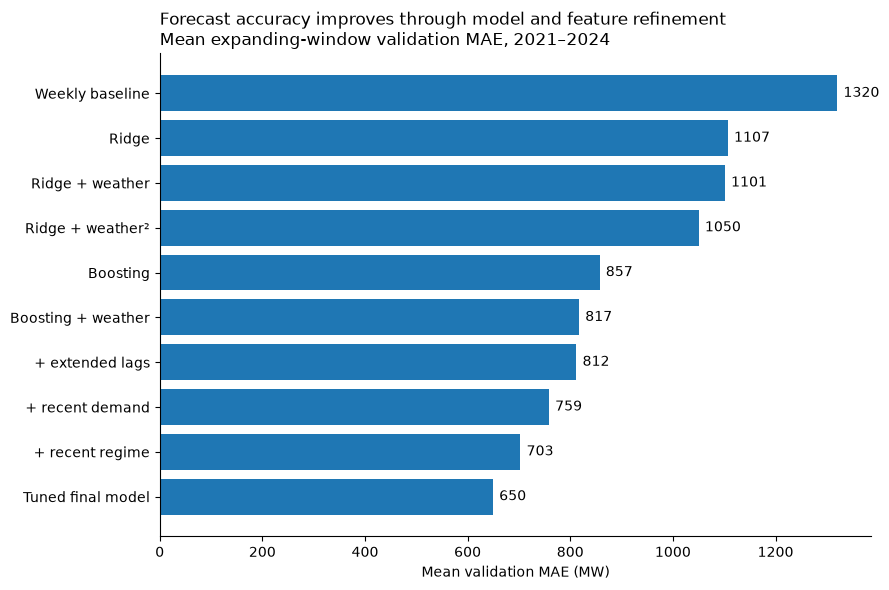

In [81]:
model_progression = pd.Series({
    "Weekly baseline": (
        baseline_metrics
        .xs("lag_168", level="model")["MAE"]
        .mean()
    ),
    "Ridge": ridge_metrics["MAE"].mean(),
    "Ridge + weather": ridge_weather_metrics["MAE"].mean(),
    "Ridge + weather²": (
        ridge_weather_squared_metrics["MAE"].mean()
    ),
    "Boosting": boost_basic_metrics["MAE"].mean(),
    "Boosting + weather": boost_weather_metrics["MAE"].mean(),
    "+ extended lags": (
        boost_extended_lag_metrics["MAE"].mean()
    ),
    "+ recent demand": boost_recent_metrics["MAE"].mean(),
    "+ recent regime": boost_regime_metrics["MAE"].mean(),
    "Tuned final model": (
        final_validation_metrics["MAE"].mean()
    ),
})

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.barh(
    model_progression.index,
    model_progression.values,
)

ax.invert_yaxis()

ax.set_xlabel("Mean validation MAE (MW)")
ax.set_title(
    "Forecast accuracy improves through model and feature refinement\n"
    "Mean expanding-window validation MAE, 2021–2024",
    loc="left",
)

for bar, value in zip(bars, model_progression.values):
    ax.text(
        value + 12,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.0f}",
        va="center",
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## 6. Final out-of-sample evaluation

The model specification and hyperparameters are now frozen.

The final model is fitted once using all available development data
through 2024 and evaluated on the out-of-sample period beginning on
1 January 2025.

No model or feature choices are modified based on test performance.

In [82]:
final_model_fitted = clone(final_model)

final_model_fitted.fit(
    train_final[final_features],
    train_final[target],
)

test_prediction = final_model_fitted.predict(
    test[final_features]
)

test_metrics = regression_metrics(
    test[target],
    test_prediction,
)

test_metrics

{'MAE': 779.0728820904632,
 'RMSE': np.float64(1196.013792756293),
 'MAPE': 0.03563863913305863}

In [83]:
test_results = test[
    [
        "datetime_local",
        target,
        "lag_168",
    ]
].copy()

test_results["forecast_ml"] = test_prediction

test_results

,datetime_local,demand_MW,lag_168,forecast_ml
datetime_utc,,,,
2024-12-31 23:00:00+00:00,2025-01-01 00:00:00+01:00,22924.000000,21646.500000,20971.785247
2025-01-01 00:00:00+00:00,2025-01-01 01:00:00+01:00,22185.916667,20737.250000,21096.561097
2025-01-01 01:00:00+00:00,2025-01-01 02:00:00+01:00,20952.833333,19471.416667,19989.772718
2025-01-01 02:00:00+00:00,2025-01-01 03:00:00+01:00,19774.750000,18462.083333,19386.697825
2025-01-01 03:00:00+00:00,2025-01-01 04:00:00+01:00,18973.583333,17824.333333,19084.245030
...,...,...,...,...
2026-08-31 17:00:00+00:00,2026-08-31 19:00:00+02:00,35657.500000,33578.833333,33053.991601
2026-08-31 18:00:00+00:00,2026-08-31 20:00:00+02:00,34052.166667,32280.750000,32619.275520
2026-08-31 19:00:00+00:00,2026-08-31 21:00:00+02:00,33973.833333,32508.250000,32704.862445


In [84]:
lag168_test_metrics = regression_metrics(
    test_results[target],
    test_results["lag_168"],
)

pd.DataFrame(
    {
        "ML": test_metrics,
        "lag_168": lag168_test_metrics,
    }
).T

,MAE,RMSE,MAPE
ML,779.072882,1196.013793,0.035639
lag_168,1387.341735,2129.756610,0.057321


### Exceptional-event diagnostic: April 2025 blackout

The Iberian blackout is retained in the all-events test set. The
shaded interval below is excluded only from the separately reported
normal-operation metrics.

In [85]:
blackout_start = pd.Timestamp(
    "2025-04-28 12:00",
    tz="Europe/Madrid",
)

blackout_end = pd.Timestamp(
    "2025-04-29 07:00",
    tz="Europe/Madrid",
)

test_results["is_blackout"] = (
    (test_results["datetime_local"] >= blackout_start)
    & (test_results["datetime_local"] < blackout_end)
)

print("Blackout hours:", test_results["is_blackout"].sum())

assert test_results["is_blackout"].sum() == 19

Blackout hours: 19


In [86]:
normal_operation = test_results[
    ~test_results["is_blackout"]
]

normal_ml_metrics = regression_metrics(
    normal_operation[target],
    normal_operation["forecast_ml"],
)

normal_lag168_metrics = regression_metrics(
    normal_operation[target],
    normal_operation["lag_168"],
)

comparison = pd.DataFrame({
    "ML all-events": test_metrics,
    "ML normal-operation": normal_ml_metrics,
    "lag_168 all-events": lag168_test_metrics,
    "lag_168 normal-operation": normal_lag168_metrics,
}).T

comparison

,MAE,RMSE,MAPE
ML all-events,779.072882,1196.013793,0.035639
ML normal-operation,762.924150,1075.196596,0.026657
lag_168 all-events,1387.341735,2129.756610,0.057321
lag_168 normal-operation,1372.491805,2067.960837,0.048576


In [87]:
blackout_metrics = regression_metrics(
    test_results.loc[
        test_results["is_blackout"],
        target,
    ],
    test_results.loc[
        test_results["is_blackout"],
        "forecast_ml",
    ],
)

blackout_metrics

{'MAE': 13164.300285762658,
 'RMSE': np.float64(14556.159594001338),
 'MAPE': 6.92395093118802}

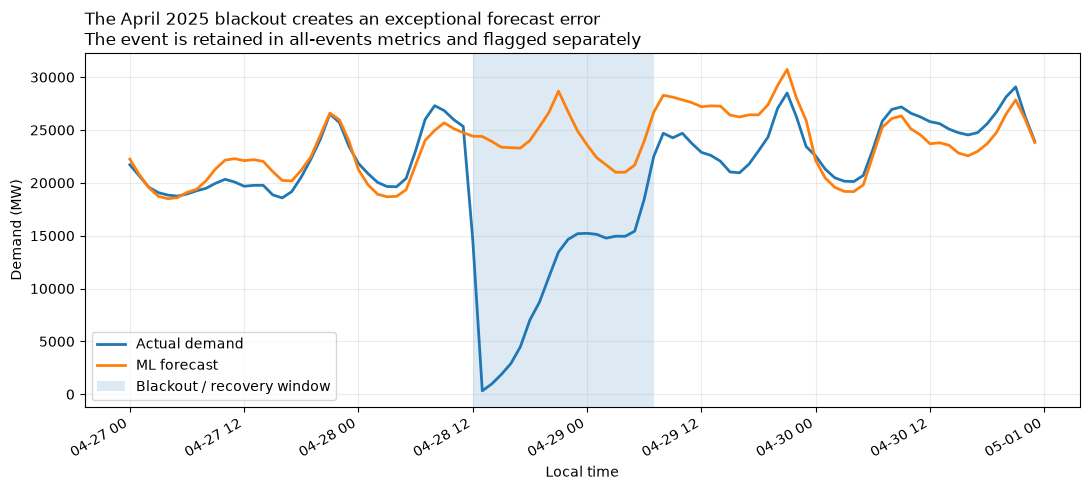

In [88]:
plot_start = pd.Timestamp(
    "2025-04-27 00:00",
    tz="Europe/Madrid",
)

plot_end = pd.Timestamp(
    "2025-04-30 23:59",
    tz="Europe/Madrid",
)

blackout_window = test_results[
    (test_results["datetime_local"] >= plot_start)
    & (test_results["datetime_local"] <= plot_end)
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    blackout_window["datetime_local"],
    blackout_window[target],
    label="Actual demand",
    linewidth=2,
)

ax.plot(
    blackout_window["datetime_local"],
    blackout_window["forecast_ml"],
    label="ML forecast",
    linewidth=2,
)

ax.axvspan(
    blackout_start,
    blackout_end,
    alpha=0.15,
    label="Blackout / recovery window",
)

ax.set_ylabel("Demand (MW)")
ax.set_xlabel("Local time")

ax.set_title(
    "The April 2025 blackout creates an exceptional forecast error\n"
    "The event is retained in all-events metrics and flagged separately",
    loc="left",
)

ax.legend()
ax.grid(alpha=0.25)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 7. Final forecast artifact

The full out-of-sample forecast is saved for downstream benchmark and
procurement analysis.

The blackout period is retained in the dataset and explicitly flagged
rather than removed.

In [89]:
forecast_output = test_results[
    [
        "datetime_local",
        target,
        "forecast_ml",
        "is_blackout",
    ]
].copy()

processed_dir = (
    project_root
    / "data"
    / "processed"
)

processed_dir.mkdir(
    parents=True,
    exist_ok=True,
)

forecast_output.to_csv(
    processed_dir / "forecast_boost.csv",
    index=True,
)

forecast_output

,datetime_local,demand_MW,forecast_ml,is_blackout
datetime_utc,,,,
2024-12-31 23:00:00+00:00,2025-01-01 00:00:00+01:00,22924.000000,20971.785247,False
2025-01-01 00:00:00+00:00,2025-01-01 01:00:00+01:00,22185.916667,21096.561097,False
2025-01-01 01:00:00+00:00,2025-01-01 02:00:00+01:00,20952.833333,19989.772718,False
2025-01-01 02:00:00+00:00,2025-01-01 03:00:00+01:00,19774.750000,19386.697825,False
2025-01-01 03:00:00+00:00,2025-01-01 04:00:00+01:00,18973.583333,19084.245030,False
...,...,...,...,...
2026-08-31 17:00:00+00:00,2026-08-31 19:00:00+02:00,35657.500000,33053.991601,False
2026-08-31 18:00:00+00:00,2026-08-31 20:00:00+02:00,34052.166667,32619.275520,False
2026-08-31 19:00:00+00:00,2026-08-31 21:00:00+02:00,33973.833333,32704.862445,False


In [90]:
assert len(forecast_output) == len(test_results)
assert forecast_output["is_blackout"].sum() == 19